# Исторические покупки с предполагаемыми касаниями

Первый этап — генерация данных и описание выборки. Измените параметры следующей ячейки и выполните **Restart Kernel → Run All**. Ноутбук запускается из корня репозитория или папки notebooks, нужны pandas, numpy и matplotlib.

Все исторические покупки, курсы и суммы сохраняются. Касания, заявки и непокупающая аудитория вымышлены. Публикации берутся из исторической разметки. Пост выбирается равновероятно среди доступных по времени, без предпочтений по категории или курсу. Наличие касания не подтверждает влияние поста на покупку.

Суммы затрат неизвестны. Распределение выручки и ROMI на этом этапе не рассчитываются. Выходные таблицы составляют самостоятельную экспериментальную базу данных в CSV.

In [1]:
# ГЛОБАЛЬНЫЕ ПАРАМЕТРЫ — изменяйте здесь
SEED = 42
CONTRACT_VERSION = '1.3'
BUYER_TOUCH_COUNTS = [0, 1, 2, 3]
BUYER_TOUCH_PROBABILITIES = [0.30, 0.35, 0.25, 0.10]
ATTRIBUTION_WINDOW_DAYS = 30
BUYER_DELAY_SCALE_DAYS = 7.0
NONBUYERS_PER_BUYER = 3.0
NONBUYER_EXTRA_TOUCHES_LAMBDA = 1.0  # число касаний = 1 + Poisson(lambda)
NONBUYER_DELAY_SCALE_DAYS = 7.0
LEAD_PROBABILITY = 0.20  # вероятность заявки после каждого касания в обеих группах
TIMEZONE = 'Europe/Moscow'  # исходные времена считаем московскими
MIN_GAP_SECONDS = 1  # строго после публикации/предыдущей покупки и до оплаты
OUTPUT_SUBDIR = 'outputs/experiments/history_enrichment'

### Категории покупки
`has_generated_touches` — есть сгенерированные касания; `no_generated_touches` — их нет. Причина отсутствия хранится отдельно: ноль по распределению, нет подходящих публикаций или нет допустимого временного интервала. Исторический источник всех покупок остаётся неизвестным (`historical_source=unknown`).


## Правила генерации

Для покупки сначала выбирается число касаний из заданного дискретного распределения. Затем для каждого касания равновероятно выбирается доступный пост **с возвращением**, поэтому повторные касания одного поста возможны. Задержка назад от покупки имеет экспоненциальное распределение, условное на допустимом интервале. Нижняя граница времени — максимум даты публикации, предыдущей покупки и начала окна 30 дней. Если кандидатов нет, все запрошенные касания этой покупки теряются, и это отражается отдельно.

Для непокупателя выбирается 1 + Poisson(lambda) касаний. Задержка вперёд от публикации экспоненциальная, ограниченная началом и концом наблюдения. Посты выбираются равновероятно среди тех, которые допускают касание в этом периоде. Период наблюдения заканчивается в полночь после последнего дня исторических продаж. Все генерируемые события находятся внутри периода наблюдения. Нижняя граница касания дополнительно ограничена началом этого периода.

**7 дней — параметр исходной экспоненты.** После ограничения датами фактическое среднее будет другим. Само ограничение не создаёт скоплений на границе: используется усечённое распределение, а не обрезание значений.

Заявка появляется после касания с вероятностью LEAD_PROBABILITY. Её время равномерно выбирается между касанием и покупкой (для покупателя) либо концом периода (для непокупателя). С покупкой связывается только последняя из созданных для неё заявок. Остальные сохраняются без связи с оплатой. Это условная связь генератора.

В начале истории предыдущие покупки неизвестны. Отсутствие подходящих публикаций может отражать неполную историю постов. Поэтому ноль касаний не означает установленный органический спрос.

In [2]:
from pathlib import Path
from decimal import Decimal
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'data/raw/base.csv').exists())
OUTPUT = ROOT / OUTPUT_SUBDIR
OUTPUT.mkdir(parents=True, exist_ok=True)

assert len(BUYER_TOUCH_COUNTS) == len(BUYER_TOUCH_PROBABILITIES) > 0
assert all(isinstance(v, int) and v >= 0 for v in BUYER_TOUCH_COUNTS)
assert len(set(BUYER_TOUCH_COUNTS)) == len(BUYER_TOUCH_COUNTS)
assert all(np.isfinite(v) and v >= 0 for v in BUYER_TOUCH_PROBABILITIES)
assert np.isclose(sum(BUYER_TOUCH_PROBABILITIES), 1)
assert all(np.isfinite(v) and v > 0 for v in [ATTRIBUTION_WINDOW_DAYS, BUYER_DELAY_SCALE_DAYS, NONBUYER_DELAY_SCALE_DAYS, MIN_GAP_SECONDS])
assert np.isfinite(NONBUYERS_PER_BUYER) and NONBUYERS_PER_BUYER >= 0
assert np.isfinite(NONBUYER_EXTRA_TOUCHES_LAMBDA) and NONBUYER_EXTRA_TOUCHES_LAMBDA >= 0
assert 0 <= LEAD_PROBABILITY <= 1

# Независимые потоки случайности для числа касаний, времени и заявок.
streams = np.random.SeedSequence(SEED).spawn(4)
count_rng, buyer_rng, nonbuyer_rng, lead_rng = [np.random.default_rng(s) for s in streams]

## Подготовка истории без потери сумм

Один заказ определяется студентом и точным временем. Исходная строка становится позицией заказа, её сумма сохраняется до копейки. Совпадающие строки не удаляются без доказательства дубля. Покупателям присваиваются экспериментальные ID; связь между повторными покупками сохраняется.

При некорректных обязательных полях выполнение останавливается. Разметка категорий и продуктов постов наследуется из EDA и может содержать ошибки. История содержит публикации собственного канала, а не полный перечень оплаченной рекламы.

In [3]:
sales_path = ROOT / 'data/raw/base.csv'
posts_path = ROOT / 'data/processed/analysis_posts_v2.csv'
raw = pd.read_csv(sales_path, dtype=str)
assert raw.notna().all().all(), 'В исходных продажах есть пропуски'
sales = raw.rename(columns={'Номер студента': 'student_id', 'Сумма': 'raw_amount', 'Курс': 'course', 'Время': 'raw_time'}).copy()
sales['timestamp'] = pd.to_datetime(sales.raw_time, format='%d.%m.%Y %H:%M:%S', errors='raise').dt.tz_localize(TIMEZONE)

def to_cents(value):
    amount = Decimal(''.join(value.split()).replace(',', '.'))
    assert amount.is_finite() and amount >= 0 and amount * 100 == (amount * 100).to_integral_value()
    return int(amount * 100)

sales['amount_cents'] = sales.raw_amount.map(to_cents)
student_ids = sorted(sales.student_id.unique())
user_map = {student: f'history_user_{i+1}' for i, student in enumerate(student_ids)}
sales['user_id_hash'] = sales.student_id.map(user_map)
orders = sales.groupby(['user_id_hash', 'timestamp'], as_index=False).amount_cents.sum().sort_values(['user_id_hash', 'timestamp']).reset_index(drop=True)
orders['order_id'] = [f'history_order_{i+1}' for i in range(len(orders))]
orders['amount'] = orders.amount_cents / 100
orders['previous_order_time'] = orders.groupby('user_id_hash').timestamp.shift()
orders['record_origin'] = 'historical_purchase'
orders['lead_id'] = pd.Series(pd.NA, index=orders.index, dtype='Int64')
order_keys = orders.set_index(['user_id_hash', 'timestamp']).order_id
source_keys = pd.MultiIndex.from_frame(sales[['user_id_hash', 'timestamp']])
assert order_keys.index.is_unique and source_keys.isin(order_keys.index).all()
items = sales.copy()
items['order_id'] = order_keys.reindex(source_keys).to_numpy()
items = items[['order_id', 'course', 'amount_cents']].copy()
items.insert(0, 'item_id', np.arange(1, len(items)+1))
items['amount'] = items.amount_cents / 100
items['record_origin'] = 'historical_purchase_item'

posts = pd.read_csv(posts_path)
assert posts.post_id.notna().all() and posts.post_id.is_unique
posts['publication_time'] = pd.to_datetime(posts.event_timestamp, errors='raise').dt.tz_localize(TIMEZONE)
posts['placement_id'] = 'history_post_' + posts.post_id.astype(str)
posts = posts.sort_values(['publication_time', 'placement_id']).reset_index(drop=True)
posts['record_origin'] = 'historical_post_with_eda_labels'
posts['cost'] = np.nan
posts['cost_known'] = False
observation_start = orders.timestamp.min().normalize()
observation_end = orders.timestamp.max().normalize() + pd.Timedelta(days=1)
period_days = (observation_end - observation_start).days
print(f'{len(orders)} заказов, {len(student_ids)} покупателей, {len(items)} позиций, {items.course.nunique()} курсов')
print(f'Выручка {orders.amount.sum():,.2f} ₽; {period_days} дней; {len(posts)} публикаций')

628 заказов, 606 покупателей, 795 позиций, 18 курсов
Выручка 5,904,671.67 ₽; 38 дней; 48 публикаций


## Генерация касаний и заявок

В touches поле generation_order_id фиксирует, для какой покупки создано касание. Это служебное поле генерации. В дальнейшем движок атрибуции должен самостоятельно выбирать касания по пользователю и времени.

При изменении параметров меняются только сгенерированные данные. Покупки и позиции проверяются на точное совпадение с источником.

In [4]:
gap = pd.Timedelta(seconds=MIN_GAP_SECONDS)
window = pd.Timedelta(days=ATTRIBUTION_WINDOW_DAYS)
touch_rows, order_diagnostics = [], []


def truncated_exponential(rng, lower, upper, scale):
    # Условная экспонента на [lower, upper], без rejection sampling и clipping.
    assert 0 <= lower < upper
    mass = -np.expm1(-(upper-lower)/scale)
    return lower - scale * np.log1p(-rng.random() * mass)


for order in orders.itertuples():
    requested = int(count_rng.choice(BUYER_TOUCH_COUNTS, p=BUYER_TOUCH_PROBABILITIES))
    start = max(observation_start, order.timestamp - window)
    if pd.notna(order.previous_order_time):
        start = max(start, order.previous_order_time + gap)
    end = order.timestamp - gap
    candidates = posts.loc[posts.publication_time.add(gap).lt(end)]
    if start >= end:
        candidates = candidates.iloc[:0]
    actual = requested if len(candidates) else 0
    reason = None
    if requested == 0:
        reason = 'sampled_zero'
    elif start >= end:
        reason = 'no_valid_interval'
    elif candidates.empty:
        reason = 'no_available_posts'
    category = 'has_generated_touches' if actual else 'no_generated_touches'
    order_diagnostics.append((order.order_id, requested, actual, len(candidates), category, reason))
    for _ in range(actual):
        post = candidates.iloc[int(buyer_rng.integers(len(candidates)))]
        earliest = max(start, post.publication_time + gap)
        delay_min = gap.total_seconds() / 86400
        delay_max = (order.timestamp-earliest).total_seconds() / 86400
        delay = truncated_exponential(buyer_rng, delay_min, delay_max, BUYER_DELAY_SCALE_DAYS)
        touch_time = order.timestamp - pd.Timedelta(days=delay)
        touch_rows.append((len(touch_rows)+1, order.user_id_hash, post.placement_id, touch_time, order.order_id, 'buyer'))

n_nonbuyers = int(round(len(student_ids) * NONBUYERS_PER_BUYER))
nonbuyer_ids = [f'synthetic_nonbuyer_{i+1}' for i in range(n_nonbuyers)]
nonbuyer_candidates = posts.loc[posts.publication_time.add(gap).lt(observation_end-gap)]
nonbuyer_missing = 0
for user_id in nonbuyer_ids:
    requested = 1 + int(count_rng.poisson(NONBUYER_EXTRA_TOUCHES_LAMBDA))
    if nonbuyer_candidates.empty:
        nonbuyer_missing += requested
        continue
    for _ in range(requested):
        post = nonbuyer_candidates.iloc[int(nonbuyer_rng.integers(len(nonbuyer_candidates)))]
        earliest = max(observation_start, post.publication_time + gap)
        latest = observation_end-gap
        lower = (earliest-post.publication_time).total_seconds()/86400
        upper = (latest-post.publication_time).total_seconds()/86400
        delay = truncated_exponential(nonbuyer_rng, lower, upper, NONBUYER_DELAY_SCALE_DAYS)
        touch_time = post.publication_time + pd.Timedelta(days=delay)
        touch_rows.append((len(touch_rows)+1, user_id, post.placement_id, touch_time, None, 'nonbuyer'))

touches = pd.DataFrame(touch_rows, columns=['touch_id', 'user_id_hash', 'placement_id', 'timestamp', 'generation_order_id', 'user_group'])
touches['timestamp'] = pd.to_datetime(touches.timestamp, utc=True).dt.tz_convert(TIMEZONE)
touches['record_origin'] = 'synthetic_touch'
order_diagnostics = pd.DataFrame(order_diagnostics, columns=['order_id', 'requested_touches', 'actual_touches', 'candidate_posts', 'touch_category', 'no_touch_reason'])
for field in ['touch_category', 'no_touch_reason']:
    orders[field] = orders.order_id.map(order_diagnostics.set_index('order_id')[field])
orders['historical_source'] = 'unknown'
users = pd.DataFrame({'user_id_hash': list(user_map.values()) + nonbuyer_ids,
                      'user_group': ['buyer']*len(student_ids) + ['nonbuyer']*n_nonbuyers,
                      'record_origin': ['historical_buyer']*len(student_ids) + ['synthetic_nonbuyer']*n_nonbuyers})
users['touches'] = users.user_id_hash.map(touches.groupby('user_id_hash').size()).fillna(0).astype(int)

lead_rows = []
order_times = orders.set_index('order_id').timestamp
for touch in touches.itertuples():
    if lead_rng.random() >= LEAD_PROBABILITY:
        continue
    end = order_times[touch.generation_order_id] if touch.user_group == 'buyer' else observation_end
    if end-touch.timestamp <= 2*gap:
        continue
    lead_time = touch.timestamp + gap + (end-touch.timestamp-2*gap)*lead_rng.random()
    lead_rows.append((len(lead_rows)+1, touch.touch_id, touch.user_id_hash, lead_time, touch.generation_order_id))
leads = pd.DataFrame(lead_rows, columns=['lead_id', 'touch_id', 'user_id_hash', 'timestamp', 'generation_order_id'])
leads['timestamp'] = pd.to_datetime(leads.timestamp, utc=True).dt.tz_convert(TIMEZONE)
leads['record_origin'] = 'synthetic_lead'
latest_leads = leads.dropna(subset=['generation_order_id']).sort_values(['timestamp','lead_id']).groupby('generation_order_id').lead_id.last()
orders['lead_id'] = orders.order_id.map(latest_leads).astype('Int64')
leads['linked_order_id'] = leads.lead_id.map(orders.dropna(subset=['lead_id']).set_index('lead_id').order_id)

## Проверки и основные цифры

Доля покупателей в общей аудитории определяется параметром NONBUYERS_PER_BUYER. Среднее касаний на человека считается по всей созданной аудитории, включая нулевые значения. Среднее касаний на заказ — только по покупкам. Заявки без связанного заказа могут принадлежать как покупателям, так и непокупателям.

In [5]:
assert orders.amount_cents.sum() == sales.amount_cents.sum() == items.amount_cents.sum()
source_totals = sales.groupby(['user_id_hash', 'timestamp']).amount_cents.sum().sort_index()
output_totals = orders.set_index(['user_id_hash', 'timestamp']).amount_cents.sort_index()
pd.testing.assert_series_equal(source_totals, output_totals)
assert items.groupby('order_id').amount_cents.sum().sort_index().equals(orders.set_index('order_id').amount_cents.sort_index())

for frame, key in [(users,'user_id_hash'),(orders,'order_id'),(items,'item_id'),
                   (posts,'placement_id'),(touches,'touch_id'),(leads,'lead_id')]:
    assert frame[key].notna().all() and frame[key].is_unique, key

def require_keys(values, keys):
    assert keys.is_unique
    assert values.notna().all() and values.isin(keys).all(), 'Потерянная ссылка'

require_keys(items.order_id, orders.order_id)
require_keys(orders.user_id_hash, users.user_id_hash)
require_keys(touches.user_id_hash, users.user_id_hash)
require_keys(touches.placement_id, posts.placement_id)
require_keys(leads.user_id_hash, users.user_id_hash)
require_keys(leads.touch_id, touches.touch_id)
require_keys(orders.lead_id.dropna(), leads.lead_id)
require_keys(leads.linked_order_id.dropna(), orders.order_id)
require_keys(leads.generation_order_id.dropna(), orders.order_id)
require_keys(touches.generation_order_id.dropna(), orders.order_id)
for frame in [orders, touches, leads]:
    assert frame.timestamp.notna().all()
    assert frame.timestamp.between(observation_start, observation_end, inclusive='left').all()

touches_with_post_time = touches.copy()  # Локальное представление для графиков, без объединения таблиц.
touches_with_post_time['publication_time'] = touches_with_post_time.placement_id.map(posts.set_index('placement_id').publication_time)
assert touches_with_post_time.timestamp.gt(touches_with_post_time.publication_time).all()
buyer_touches = touches_with_post_time.loc[touches_with_post_time.user_group.eq('buyer')].copy()
require_keys(buyer_touches.generation_order_id, orders.order_id)
order_index = orders.set_index('order_id')
buyer_touches['timestamp_touch'] = buyer_touches.timestamp
buyer_touches['timestamp_order'] = buyer_touches.generation_order_id.map(order_index.timestamp)
buyer_touches['previous_order_time'] = buyer_touches.generation_order_id.map(order_index.previous_order_time)
assert buyer_touches.user_id_hash.eq(buyer_touches.generation_order_id.map(order_index.user_id_hash)).all()
assert buyer_touches.timestamp_touch.lt(buyer_touches.timestamp_order).all()
assert (buyer_touches.timestamp_order-buyer_touches.timestamp_touch).le(window).all()
assert (buyer_touches.previous_order_time.isna() | buyer_touches.timestamp_touch.gt(buyer_touches.previous_order_time)).all()
assert not orders.user_id_hash.isin(nonbuyer_ids).any()
assert not orders.lead_id.dropna().duplicated().any()
touch_index = touches.set_index('touch_id')
assert leads.timestamp.gt(leads.touch_id.map(touch_index.timestamp)).all()
assert leads.user_id_hash.eq(leads.touch_id.map(touch_index.user_id_hash)).all()
linked_orders = orders.loc[orders.lead_id.notna()]
lead_index = leads.set_index('lead_id')
assert linked_orders.timestamp.gt(linked_orders.lead_id.map(lead_index.timestamp)).all()
assert linked_orders.user_id_hash.eq(linked_orders.lead_id.map(lead_index.user_id_hash)).all()
assert linked_orders.order_id.eq(linked_orders.lead_id.map(lead_index.linked_order_id)).all()
linked_leads = leads.loc[leads.linked_order_id.notna()]
assert linked_leads.lead_id.eq(linked_leads.linked_order_id.map(order_index.lead_id)).all()
actual_counts = orders.order_id.map(buyer_touches.generation_order_id.value_counts()).fillna(0).astype(int)
assert actual_counts.eq(orders.order_id.map(order_diagnostics.set_index('order_id').actual_touches)).all()
assert orders.touch_category.eq(np.where(actual_counts.gt(0), 'has_generated_touches', 'no_generated_touches')).all()
assert orders.loc[actual_counts.gt(0), 'no_touch_reason'].isna().all()
assert orders.loc[actual_counts.eq(0), 'no_touch_reason'].isin(['sampled_zero','no_available_posts','no_valid_interval']).all()
missing_orders = int(orders.no_touch_reason.eq('no_available_posts').sum())
summary = pd.Series({
    'Пользователи': len(users), 'Покупатели': len(student_ids), 'Доля покупателей, %': 100*len(student_ids)/len(users),
    'Непокупатели': n_nonbuyers, 'Заказы': len(orders), 'Позиции': len(items), 'Курсы': items.course.nunique(),
    'Выручка, ₽': orders.amount_cents.sum()/100, 'Касания': len(touches),
    'Касаний на пользователя': users.touches.mean(), 'Касаний на покупку': order_diagnostics.actual_touches.mean(),
    'Заявки': len(leads), 'Заказы с заявкой': int(orders.lead_id.notna().sum()),
    'Заявки без связанной оплаты': int(leads.linked_order_id.isna().sum()),
    'Покупки без касаний, %': 100*order_diagnostics.actual_touches.eq(0).mean(),
    'Покупки с потерянными касаниями из-за отсутствия постов': missing_orders,
    'Покупки без допустимого интервала': int(orders.no_touch_reason.eq('no_valid_interval').sum()),
    'Потерянные касания непокупателей': nonbuyer_missing,
})
display(summary.round(2).to_frame('Значение'))
display(orders.groupby(['touch_category','no_touch_reason'],dropna=False).size().rename('Заказы').to_frame())
print('Проверки сумм, ключей, категорий и хронологии пройдены.')


Проверки сумм, ключей, категорий и хронологии пройдены.


,Значение
Пользователи,2424.00
Покупатели,606.00
"Доля покупателей, %",25.00
Непокупатели,1818.00
Заказы,628.00
Позиции,795.00
Курсы,18.00
"Выручка, ₽",5904671.67
Касания,4323.00
Касаний на пользователя,1.78


Заказы
touch_category        no_touch_reason           
has_generated_touches NaN                    437
no_generated_touches  no_available_posts       5
                      sampled_zero           186

## Распределения

На первом графике сравниваются заданные вероятности, случайно выбранные числа касаний и фактически созданные касания. Разница последних двух возникает при отсутствии подходящих публикаций. На гистограммах задержек показаны реализованные значения после ограничения датами.

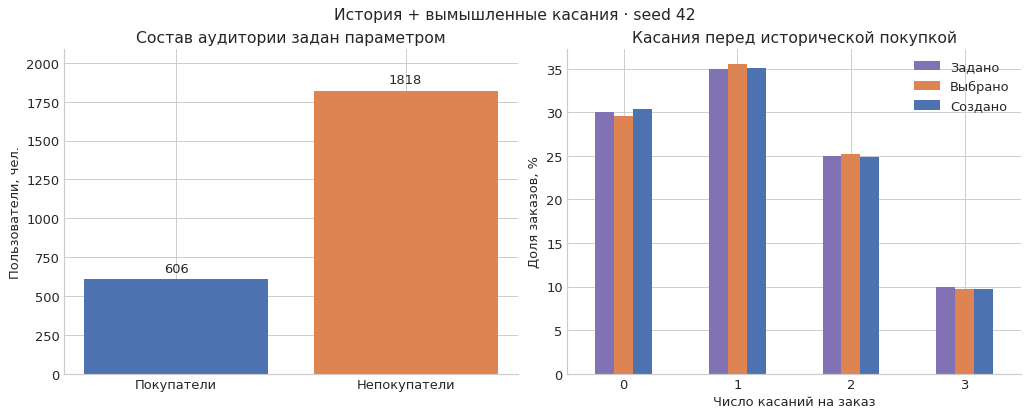

,Задано,Выбрано,Создано
0,30.0,29.62,30.41
1,35.0,35.51,35.03
2,25.0,25.16,24.84
3,10.0,9.71,9.71


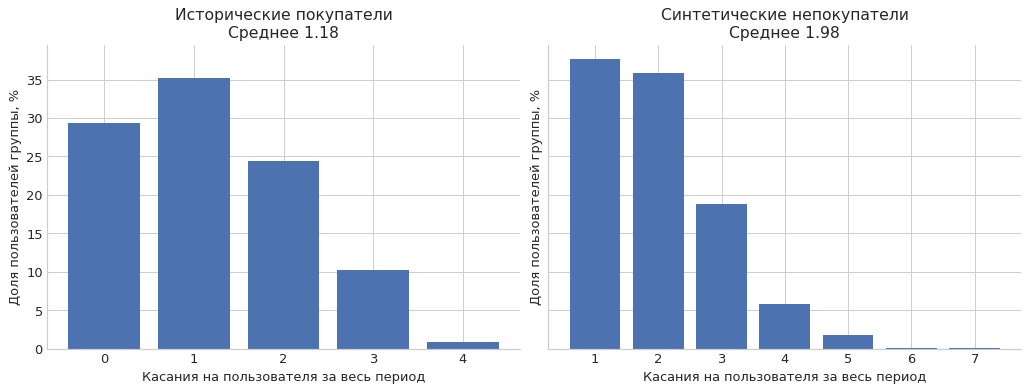

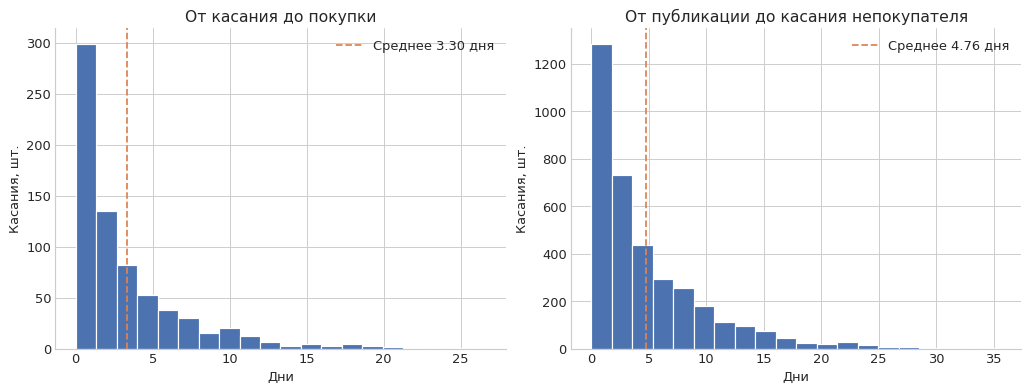

In [6]:
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False, 'svg.fonttype': 'none'})
BLUE, ORANGE, PURPLE = '#4C72B0', '#DD8452', '#8172B3'

def save_chart(fig, name):
    fig.savefig(OUTPUT / f'{name}.svg', bbox_inches='tight')
    fig.savefig(OUTPUT / f'{name}.png', dpi=140, bbox_inches='tight')
    plt.show()

categories = sorted(set(BUYER_TOUCH_COUNTS) | {0})
distribution = pd.DataFrame(index=categories)
distribution['Задано'] = pd.Series(dict(zip(BUYER_TOUCH_COUNTS, BUYER_TOUCH_PROBABILITIES))).reindex(categories, fill_value=0)*100
for col, label in [('requested_touches', 'Выбрано'), ('actual_touches', 'Создано')]:
    distribution[label] = order_diagnostics[col].value_counts(normalize=True).reindex(categories, fill_value=0)*100
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), layout='constrained')
bars = axes[0].bar(['Покупатели', 'Непокупатели'], [len(student_ids), n_nonbuyers], color=[BLUE,ORANGE])
axes[0].bar_label(bars, padding=4)
axes[0].set(title='Состав аудитории задан параметром', ylabel='Пользователи, чел.', ylim=(0,max(len(student_ids),n_nonbuyers)*1.15))
distribution.plot.bar(ax=axes[1], color=[PURPLE, ORANGE, BLUE], rot=0)
axes[1].set(title='Касания перед исторической покупкой', xlabel='Число касаний на заказ', ylabel='Доля заказов, %')
fig.suptitle(f'История + вымышленные касания · seed {SEED}')
save_chart(fig, '01_population_and_order_touches')
display(distribution.round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True, layout='constrained')
for ax, group, label in zip(axes, ['buyer','nonbuyer'], ['Исторические покупатели','Синтетические непокупатели']):
    values=users.loc[users.user_group.eq(group), 'touches']
    frequencies=values.value_counts().sort_index()
    ax.bar(frequencies.index, frequencies/max(len(values),1)*100, color=BLUE)
    ax.set(title=f'{label}\nСреднее {values.mean():.2f}', xlabel='Касания на пользователя за весь период', ylabel='Доля пользователей группы, %')
save_chart(fig, '02_user_touches')

buyer_delays = (buyer_touches.timestamp_order-buyer_touches.timestamp_touch).dt.total_seconds()/86400
nonbuyer_touches = touches_with_post_time.loc[touches_with_post_time.user_group.eq('nonbuyer')]
nonbuyer_delays = (nonbuyer_touches.timestamp-nonbuyer_touches.publication_time).dt.total_seconds()/86400
fig, axes = plt.subplots(1,2,figsize=(12,4.5),layout='constrained')
for ax, values, title in zip(axes, [buyer_delays,nonbuyer_delays], ['От касания до покупки', 'От публикации до касания непокупателя']):
    ax.hist(values,bins=20,color=BLUE,edgecolor='white')
    if len(values):
        ax.axvline(values.mean(),color=ORANGE,linestyle='--',label=f'Среднее {values.mean():.2f} дня')
        ax.legend()
    ax.set(title=title,xlabel='Дни',ylabel='Касания, шт.')
save_chart(fig,'03_delays')

## Курсы и календарь

Все курсы сохранены. На графике количества продаж считаются позиции заказа: покупка двух курсов даёт две позиции и один заказ. Выручка по курсам берётся из исходных сумм позиций. Акция не выводится из наличия нескольких курсов.

Календарь показывает исторические покупки и вымышленные события. Сходство их динамики частично создаётся генерацией касаний перед известными покупками.

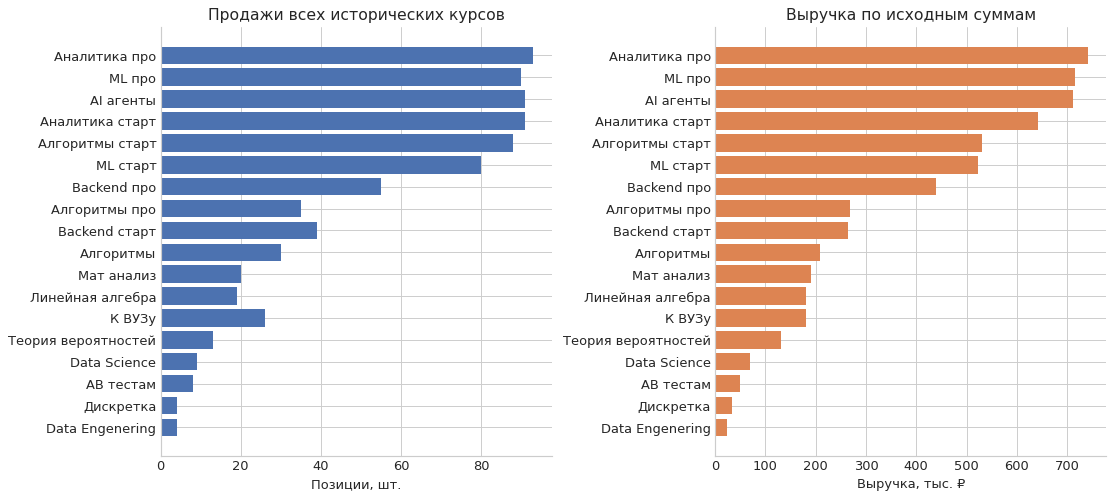

,items,revenue
course,,
Data Engenering,4,24845.00
Дискретка,4,34415.00
АВ тестам,8,49610.00
Data Science,9,69295.00
Теория вероятностей,13,132107.50
К ВУЗу,26,180250.00
Линейная алгебра,19,180665.00
Мат анализ,20,191382.50
Алгоритмы,30,209482.50


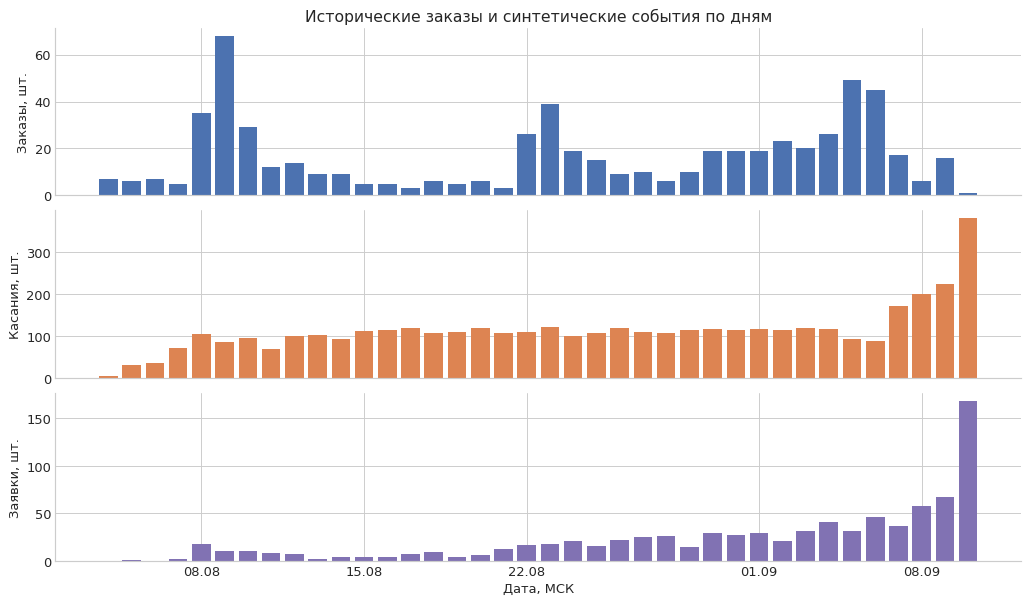

In [7]:
products = items.groupby('course').agg(items=('item_id','size'), revenue=('amount','sum')).sort_values('revenue')
fig, axes=plt.subplots(1,2,figsize=(13,max(5,len(products)*.32)),layout='constrained')
axes[0].barh(products.index,products['items'],color=BLUE)
axes[0].set(title='Продажи всех исторических курсов',xlabel='Позиции, шт.')
axes[1].barh(products.index,products.revenue/1000,color=ORANGE)
axes[1].set(title='Выручка по исходным суммам',xlabel='Выручка, тыс. ₽')
save_chart(fig,'04_products')
display(products)

calendar=pd.date_range(observation_start,observation_end-pd.Timedelta(days=1),freq='D')
daily=pd.DataFrame(index=calendar)
daily['Заказы']=orders.groupby(orders.timestamp.dt.normalize()).size().reindex(calendar,fill_value=0)
daily['Касания']=touches.groupby(touches.timestamp.dt.normalize()).size().reindex(calendar,fill_value=0)
daily['Заявки']=leads.groupby(leads.timestamp.dt.normalize()).size().reindex(calendar,fill_value=0)
fig,axes=plt.subplots(3,1,figsize=(12,7),sharex=True,layout='constrained')
for ax,(column,color) in zip(axes,zip(daily.columns,[BLUE,ORANGE,PURPLE])):
    ax.bar(daily.index,daily[column],color=color)
    ax.set(ylabel=f'{column}, шт.')
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%d.%m',tz=TIMEZONE))
axes[0].set_title('Исторические заказы и синтетические события по дням')
axes[-1].set_xlabel('Дата, МСК')
save_chart(fig,'05_calendar')

## Экспорт

CSV сохраняются в папку OUTPUT_SUBDIR. Файл manifest.json содержит параметры, происхождение таблиц и хеши исходных файлов. При новом запуске эти результаты перезаписываются. Для сохранения альтернативного предположения измените OUTPUT_SUBDIR.

Покупки и публикации имеют историческое происхождение, касания и заявки — синтетическое. Весь набор является экспериментальным. Эти признаки нельзя использовать как доказательство реальной воронки или эффекта рекламы.

In [8]:
tables={'users':users,'orders':orders,'order_items':items,'placements':posts.drop(columns=['post_text']),
        'touches':touches,'leads':leads,'order_diagnostics':order_diagnostics}
for name,frame in tables.items():
    frame.to_csv(OUTPUT / f'{name}.csv',index=False)
summary.to_csv(OUTPUT / 'summary.csv',header=['value'])
distribution.to_csv(OUTPUT / 'touch_distribution.csv',index_label='touches_per_order')
products.to_csv(OUTPUT / 'products.csv')
daily.to_csv(OUTPUT / 'daily.csv',index_label='date')
parameter_names=['SEED','BUYER_TOUCH_COUNTS','BUYER_TOUCH_PROBABILITIES','ATTRIBUTION_WINDOW_DAYS',
                 'BUYER_DELAY_SCALE_DAYS','NONBUYERS_PER_BUYER','NONBUYER_EXTRA_TOUCHES_LAMBDA',
                 'NONBUYER_DELAY_SCALE_DAYS','LEAD_PROBABILITY','TIMEZONE','MIN_GAP_SECONDS','OUTPUT_SUBDIR']
manifest={'experiment_only':True, 'contract_version':CONTRACT_VERSION,
          'as_of':pd.Timestamp.now(tz=TIMEZONE).isoformat(), 'scope':'current_generation_only',
          'analysis_units':['user','order','order_item','touch','lead','placement'],
          'placement_ids':posts.placement_id.tolist(), 'attribution_model':None,
          'parameters':{name:globals()[name] for name in parameter_names},
          'sources':{str(p.relative_to(ROOT)):hashlib.sha256(p.read_bytes()).hexdigest() for p in [sales_path,posts_path]},
          'observation_start':str(observation_start),'observation_end_exclusive':str(observation_end),
          'checks':'passed','historical_order_count':len(orders),'historical_revenue_cents':int(orders.amount_cents.sum()),
          'provenance':'Purchases and publications from history; touches, leads and nonbuyers simulated',
          'software':{'numpy':np.__version__,'pandas':pd.__version__}}
(OUTPUT / 'manifest.json').write_text(json.dumps(manifest,ensure_ascii=False,indent=2)+'\n')
print(f'Данные и графики сохранены в {OUTPUT.relative_to(ROOT)}')

Данные и графики сохранены в outputs/experiments/history_enrichment
